<a href="https://colab.research.google.com/github/belgaa-a/EksploracjaDanych/blob/main/AW_zajecia4_2910.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.


---1---


,liczba_brakow,odsetek_brakow_%
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467



---2---


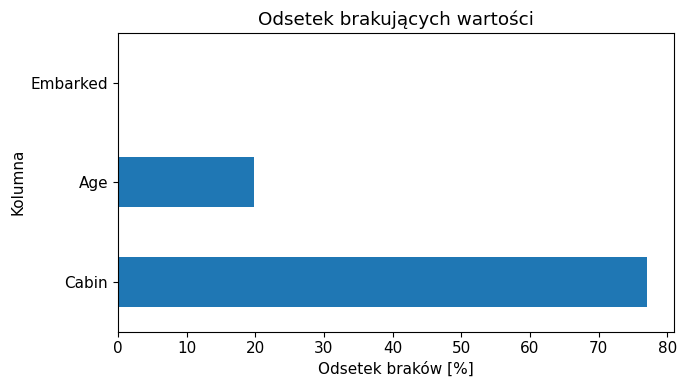

In [4]:
# TODO
print("\n---1---")
braki = titanic.isna().sum()
odsetek = titanic.isna().mean() * 100
podsumowanie_brakow = pd.DataFrame({"liczba_brakow": braki, "odsetek_brakow_%": odsetek})
podsumowanie_brakow = podsumowanie_brakow[podsumowanie_brakow["liczba_brakow"] > 0].sort_values("odsetek_brakow_%", ascending=False)
display(podsumowanie_brakow)
print("\n---2---")
ax = podsumowanie_brakow["odsetek_brakow_%"].plot.barh()
ax.set_xlabel("Odsetek braków [%]")
ax.set_ylabel("Kolumna")
ax.set_title("Odsetek brakujących wartości")
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

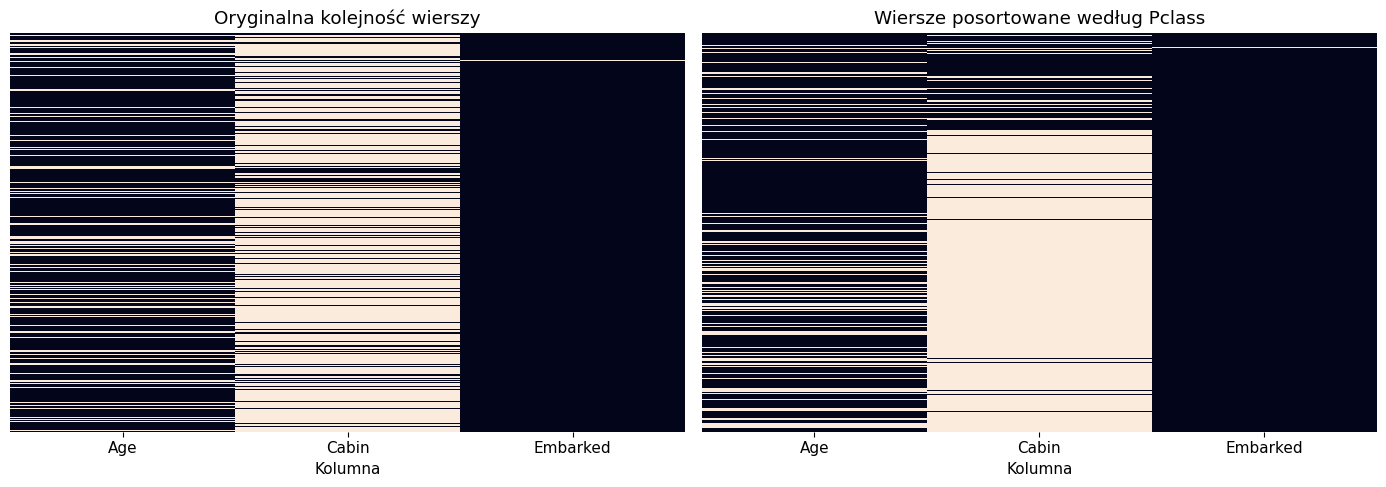

In [5]:
kolumny = ["Age", "Cabin", "Embarked"]

# TODO
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(titanic[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("Oryginalna kolejność wierszy")
axes[0].set_xlabel("Kolumna")
posortowany = titanic.sort_values("Pclass")
sns.heatmap(posortowany[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("Wiersze posortowane według Pclass")
axes[1].set_xlabel("Kolumna")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:*

Po posortowaniu można zauważyć że występowanie braków nie jest przypadkowe. Często braki wiążą się z klasą pasażera. Pozwala to zauważyć wzorzec ale nie dowodzi przyczyny.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?


---2---
Odsetek braków wieku według klasy [%]:


,Age
Pclass,
1,13.888889
2,5.978261
3,27.698574


Odsetek braków wieku według płci [%]:


,Age
Sex,
female,16.878981
male,21.490468



---3---
Odsetek ocalałych [%]:


,Survived
Znany wiek,40.616246
Brak wieku,29.378531



---4---


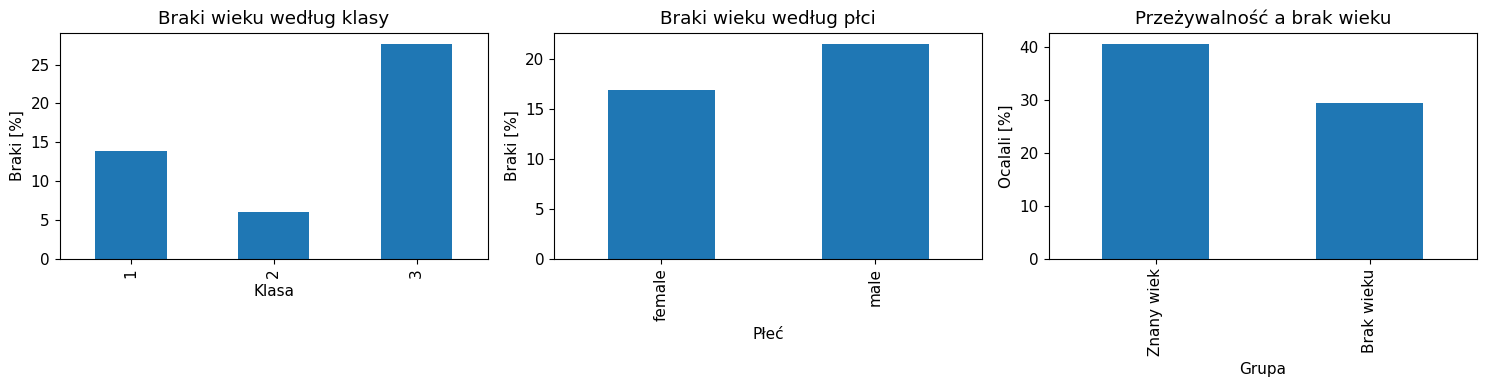

In [6]:
brak_wieku = titanic["Age"].isna()

# TODO
print("\n---2---")
braki_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
braki_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100

print("Odsetek braków wieku według klasy [%]:")
display(braki_klasa)

print("Odsetek braków wieku według płci [%]:")
display(braki_plec)

print("\n---3---")
przezycie = titanic.groupby(brak_wieku)["Survived"].mean() * 100
przezycie.index = ["Znany wiek", "Brak wieku"]

print("Odsetek ocalałych [%]:")
display(przezycie)

print("\n---4---")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

braki_klasa.plot.bar(ax=axes[0])
axes[0].set_title("Braki wieku według klasy")
axes[0].set_xlabel("Klasa")
axes[0].set_ylabel("Braki [%]")

braki_plec.plot.bar(ax=axes[1])
axes[1].set_title("Braki wieku według płci")
axes[1].set_xlabel("Płeć")
axes[1].set_ylabel("Braki [%]")

przezycie.plot.bar(ax=axes[2])
axes[2].set_title("Przeżywalność a brak wieku")
axes[2].set_xlabel("Grupa")
axes[2].set_ylabel("Ocalali [%]")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:*

Braki wieku nie są MCAR, ich występowanie wiąże się z klasą/płcią.

Usunięcie pasażerów bez podanego wieku zmieni odsetek ocalałych. Osoby z brakującym wiekiem mogą mieć inną przeżywalność

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [7]:
warianty = {
    "bez zmian": titanic,
    # TODO: pozostałe warianty
    "bez braków Embarked": titanic.dropna(subset=["Embarked"]),
    "bez braków Age": titanic.dropna(subset=["Age"]),
    "bez żadnych braków": titanic.dropna()
}

# TODO: tabela

wyniki = []

for nazwa, dane in warianty.items():
    wyniki.append({
        "wariant": nazwa,
        "liczba_wierszy": len(dane),
        "odsetek_ocalałych": dane["Survived"].mean() * 100,
        "odsetek_1_klasy": (dane["Pclass"] == 1).mean() * 100
    })

tabela = pd.DataFrame(wyniki).set_index("wariant")
display(tabela.round(2))

,liczba_wierszy,odsetek_ocalałych,odsetek_1_klasy
wariant,,,
bez zmian,891,38.38,24.24
bez braków Embarked,889,38.25,24.07
bez braków Age,714,40.62,26.05
bez żadnych braków,183,67.21,86.34


*Twoja odpowiedź:*

Usunięcie wszystkich wierszy zawierających braki może prowadzić do utraty dużej częsci danych i zmiany odsetek ocalałych/podróżników pierwszej klasy.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?


---3---


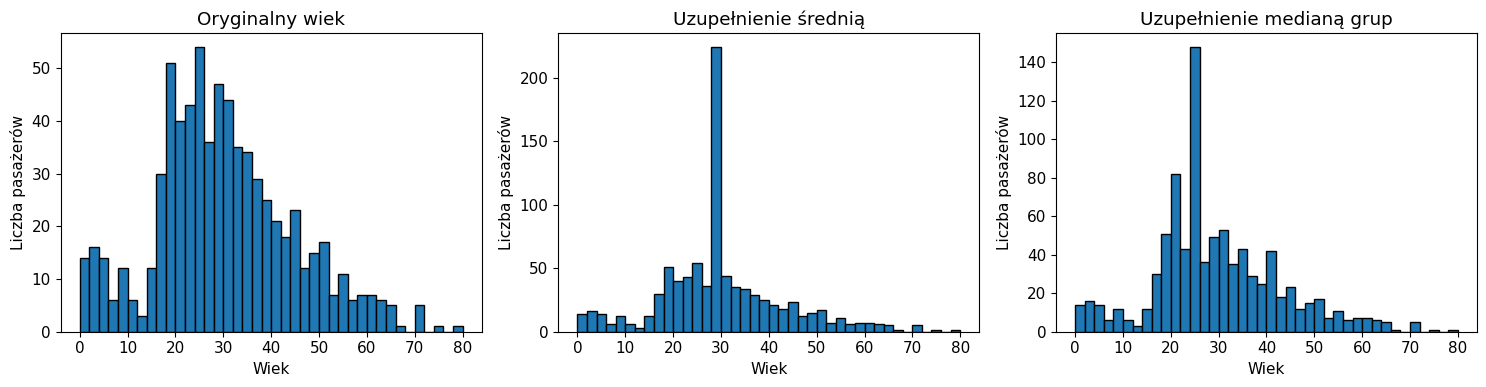


---4---


,0
Wiek oryginalny,14.53
Uzupełnienie średnią,13.00
Uzupełnienie medianą grup,13.30


In [8]:
# TODO
# 1
titanic["Age_brak"] = titanic["Age"].isna()

# 2
titanic["wiek_srednia"] = titanic["Age"].fillna(
    titanic["Age"].mean()
)
mediany_grup = titanic.groupby(
    ["Pclass", "Sex"]
)["Age"].transform("median")

titanic["wiek_grupy"] = titanic["Age"].fillna(mediany_grup)

print("\n---3---")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = np.arange(0, 82, 2)

axes[0].hist(titanic["Age"].dropna(), bins=bins, edgecolor="black")
axes[0].set_title("Oryginalny wiek")

axes[1].hist(titanic["wiek_srednia"], bins=bins, edgecolor="black")
axes[1].set_title("Uzupełnienie średnią")

axes[2].hist(titanic["wiek_grupy"], bins=bins, edgecolor="black")
axes[2].set_title("Uzupełnienie medianą grup")

for ax in axes:
    ax.set_xlabel("Wiek")
    ax.set_ylabel("Liczba pasażerów")

plt.tight_layout()
plt.show()

print("\n---4---")
odchylenia = pd.Series({
    "Wiek oryginalny": titanic["Age"].std(),
    "Uzupełnienie średnią": titanic["wiek_srednia"].std(),
    "Uzupełnienie medianą grup": titanic["wiek_grupy"].std()
})

display(odchylenia.round(2))

*Twoja odpowiedź:*

Uzupełnianie braków średniej powoduje skupienie wartości wokół jednej liczby, powoduje to zmniejszenie odchylenia standardowego oraz zmiane rozkładu wieku.

Mediana obliczona osobno dla grup lepiej odzwierciedla różnicę między grupami.

Obie metody zniekształcają jednak rozkład danych

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

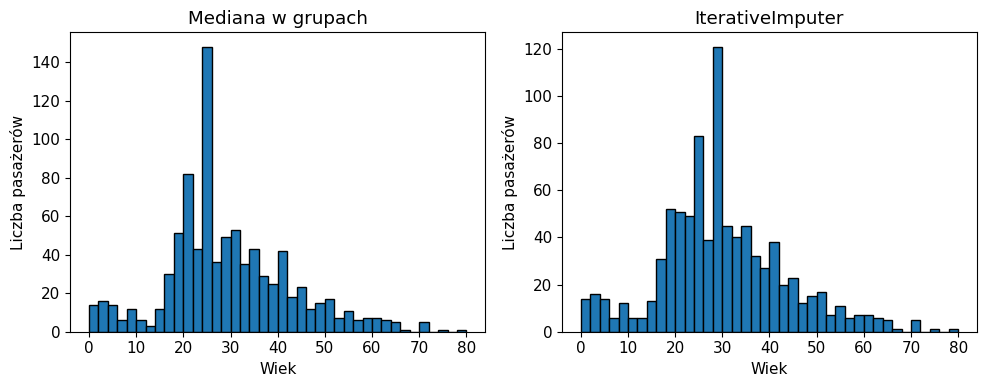

,0
Wiek oryginalny,14.53
Mediana w grupach,13.30
IterativeImputer,13.64


In [9]:
# TODO
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
dane_modelu = titanic[
    ["Age", "Pclass", "SibSp", "Parch", "Fare", "Sex"]
].copy()

dane_modelu["Sex"] = dane_modelu["Sex"].map({
    "male": 0,
    "female": 1
})

imputer = IterativeImputer(random_state=42, max_iter=10)

dane_po_imputacji = imputer.fit_transform(dane_modelu)

titanic["wiek_model"] = dane_po_imputacji[:, 0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bins = np.arange(0, 82, 2)

axes[0].hist(
    titanic["wiek_grupy"],
    bins=bins,
    edgecolor="black"
)
axes[0].set_title("Mediana w grupach")

axes[1].hist(
    titanic["wiek_model"],
    bins=bins,
    edgecolor="black"
)
axes[1].set_title("IterativeImputer")

for ax in axes:
    ax.set_xlabel("Wiek")
    ax.set_ylabel("Liczba pasażerów")

plt.tight_layout()
plt.show()

odchylenia = pd.Series({
    "Wiek oryginalny": titanic["Age"].std(),
    "Mediana w grupach": titanic["wiek_grupy"].std(),
    "IterativeImputer": titanic["wiek_model"].std()
})

display(odchylenia.round(2))

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [10]:
mieszkania = pd.read_csv("nieruchomosci.csv")

# TODO
display(mieszkania.dtypes.rename("typ"))
display(mieszkania.isna().sum().rename("liczba_brakow").to_frame())
print("Liczba braków wykrytych przez pandas:", int(mieszkania.isna().sum().sum()))

,typ
id,int64
miasto,object
dzielnica,object
powierzchnia,object
liczba_pokoi,int64
rok_budowy,object
pietro,object
liczba_pieter,int64
parking,object
balkon,object


,liczba_brakow
id,0
miasto,0
dzielnica,0
powierzchnia,4
liczba_pokoi,0
rok_budowy,4
pietro,0
liczba_pieter,0
parking,0
balkon,0


Liczba braków wykrytych przez pandas: 8


*Twoja odpowiedź:*

pandas nie rozpoznaje automatycznie tekstowych oznaczeń braku (?, -1, -999, itp.)

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [11]:
# TODO 1
for kol in mieszkania.columns:
    print(f"\\n--- {kol} ---")
    print(mieszkania[kol].value_counts(dropna=False).to_string())

\n--- id ---
id
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
15    1
16    1
17    1
18    1
19    1
20    1
21    1
22    1
23    1
24    1
25    1
26    1
27    1
28    1
29    1
30    1
31    1
32    1
33    1
34    1
35    1
36    1
37    1
38    1
39    1
40    1
41    1
42    1
43    1
44    1
45    1
\n--- miasto ---
miasto
Warszawa    9
Kraków      9
Wrocław     9
Poznań      9
Gdańsk      9
\n--- dzielnica ---
dzielnica
Krzyki           2
Stare Miasto     2
Grunwald         2
Śródmieście      2
Mokotów          1
Wrzeszcz         1
Krowodrza        1
Podgórze         1
Jeżyce           1
Oliwa            1
Żoliborz         1
Kazimierz        1
Psie Pole        1
Rataje           1
Siedlce          1
Praga            1
Nowa Huta        1
Fabryczna        1
Wilda            1
Przymorze        1
Ochota           1
Bronowice        1
Centrum          1
Ursynów          1
Dębniki          1
Zaspa            1
Wilanó

*Twoja odpowiedź:* …

In [12]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"]
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
display(mieszkania.dtypes.rename("typ").to_frame())
display(mieszkania.isna().sum().rename("liczba_brakow").to_frame())
print("Łączna liczba braków po rozpoznaniu ukrytych oznaczeń:", int(mieszkania.isna().sum().sum()))

,typ
id,int64
miasto,object
dzielnica,object
powierzchnia,float64
liczba_pokoi,int64
rok_budowy,float64
pietro,float64
liczba_pieter,int64
parking,object
balkon,object


,liczba_brakow
id,0
miasto,0
dzielnica,0
powierzchnia,9
liczba_pokoi,0
rok_budowy,7
pietro,3
liczba_pieter,0
parking,5
balkon,3


Łączna liczba braków po rozpoznaniu ukrytych oznaczeń: 29


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [15]:
# TODO
print(mieszkania["stan"].value_counts(dropna=False))
# Wartość chińska „很好” oznacza „bardzo dobrze”, więc ujednolicam ją z kategorią „Bardzo dobry”.
mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Bardzo dobry"})
print("\nKategorie po poprawieniu:")
print(mieszkania["stan"].value_counts(dropna=False))

stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64

Kategorie po poprawieniu:
stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

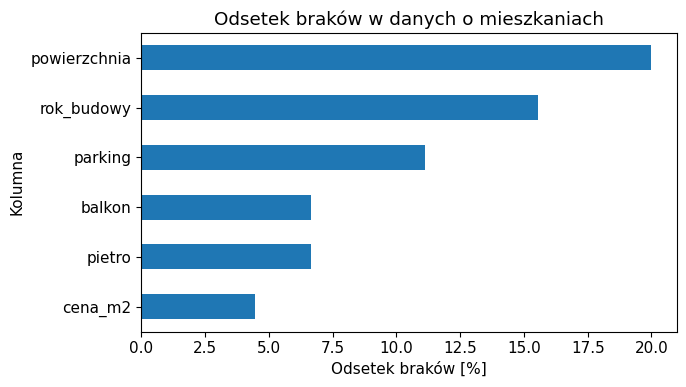

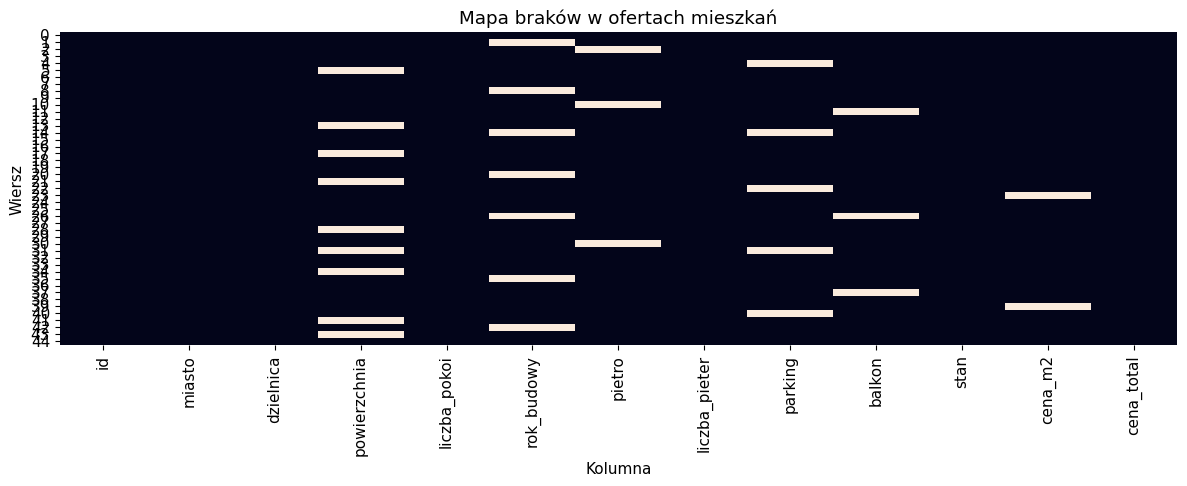

,powierzchnia,rok_budowy,pietro,parking,balkon,cena_m2
powierzchnia,1.000000e+00,-0.214599,-0.133631,-4.170558e-17,-0.133631,-0.107833
rok_budowy,-2.145988e-01,1.000000,-0.114708,4.335550e-02,0.131095,-0.092563
pietro,-1.336306e-01,-0.114708,1.000000,-9.449112e-02,-0.071429,-0.057639
parking,-4.170558e-17,0.043355,-0.094491,1.000000e+00,-0.094491,-0.076249
balkon,-1.336306e-01,0.131095,-0.071429,-9.449112e-02,1.000000,-0.057639
cena_m2,-1.078328e-01,-0.092563,-0.057639,-7.624929e-02,-0.057639,1.000000


In [16]:
# TODO
odsetek = mieszkania.isna().mean() * 100
ax = odsetek[odsetek > 0].sort_values().plot.barh()
ax.set_xlabel("Odsetek braków [%]")
ax.set_ylabel("Kolumna")
ax.set_title("Odsetek braków w danych o mieszkaniach")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
sns.heatmap(mieszkania.isna(), cbar=False, yticklabels=True)
plt.title("Mapa braków w ofertach mieszkań")
plt.xlabel("Kolumna")
plt.ylabel("Wiersz")
plt.tight_layout()
plt.show()

kolumny_z_brakami = mieszkania.columns[mieszkania.isna().any()].tolist()
display(mieszkania[kolumny_z_brakami].isna().corr())

*Twoja odpowiedź:*

Wartość w tabeli bliska 1 oznacza korelację w występowaniu braków, wartość bliska 0 wskazuje na brak wyraźnej korelacji.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [17]:
# TODO
kompletne = mieszkania.dropna(subset=["powierzchnia", "cena_m2", "cena_total"])
roznica = kompletne["cena_total"] - kompletne["powierzchnia"] * kompletne["cena_m2"]
print("Maksymalna bezwzględna różnica w kompletnych wierszach:", roznica.abs().max())

maska_pow = mieszkania["powierzchnia"].isna() & mieszkania["cena_m2"].notna() & mieszkania["cena_total"].notna()
mieszkania.loc[maska_pow, "powierzchnia"] = mieszkania.loc[maska_pow, "cena_total"] / mieszkania.loc[maska_pow, "cena_m2"]

maska_cena = mieszkania["cena_m2"].isna() & mieszkania["powierzchnia"].notna() & mieszkania["cena_total"].notna()
mieszkania.loc[maska_cena, "cena_m2"] = mieszkania.loc[maska_cena, "cena_total"] / mieszkania.loc[maska_cena, "powierzchnia"]

print("Uzupełnione powierzchnie:", int(maska_pow.sum()))
print("Uzupełnione ceny za m²:", int(maska_cena.sum()))
print("Pozostałe braki w tych dwóch kolumnach:")
display(mieszkania[["powierzchnia", "cena_m2"]].isna().sum().to_frame("liczba_brakow"))

Maksymalna bezwzględna różnica w kompletnych wierszach: 0.0
Uzupełnione powierzchnie: 9
Uzupełnione ceny za m²: 2
Pozostałe braki w tych dwóch kolumnach:


,liczba_brakow
powierzchnia,0
cena_m2,0


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [18]:
# TODO
# 1
for kol in ["rok_budowy", "pietro", "parking", "balkon"]:
    mieszkania[f"{kol}_brak"] = mieszkania[kol].isna()

print("Mediany roku budowy:")
display(pd.DataFrame({
    "mediana": [
        mieszkania["rok_budowy"].median(),
        mieszkania.groupby("miasto")["rok_budowy"].median().median(),
        mieszkania.groupby("stan")["rok_budowy"].median().median()
    ]
}, index=["całość", "mediany miast (mediana median)", "mediany stanów (mediana median)"]))
# 2
mediana_roku = mieszkania.groupby("miasto")["rok_budowy"].transform("median")
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mediana_roku).fillna(mieszkania["rok_budowy"].median())

maska_pietro = mieszkania["pietro"].isna()
mieszkania.loc[maska_pietro, "pietro"] = (mieszkania.loc[maska_pietro, "liczba_pieter"] // 2)

for kol in ["parking", "balkon"]:
    mieszkania[kol] = mieszkania[kol].fillna("nieznane")

print("Braki po uzupełnieniu:")
display(mieszkania.isna().sum().rename("liczba_brakow").to_frame())
print("Odsetek ofert z parkingiem przed uzupełnianiem:", (pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)["parking"].eq("Tak").mean() * 100).round(2), "%")
print("Odsetek ofert z parkingiem po uzupełnianiu (kategoria nieznane pozostaje osobna):", (mieszkania["parking"].eq("Tak").mean() * 100).round(2), "%")

Mediany roku budowy:


,mediana
całość,2011.5
mediany miast (mediana median),2013.0
mediany stanów (mediana median),2010.0


Braki po uzupełnieniu:


,liczba_brakow
id,0
miasto,0
dzielnica,0
powierzchnia,0
liczba_pokoi,0
rok_budowy,0
pietro,0
liczba_pieter,0
parking,0
balkon,0


Odsetek ofert z parkingiem przed uzupełnianiem: 75.56 %
Odsetek ofert z parkingiem po uzupełnianiu (kategoria nieznane pozostaje osobna): 75.56 %


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

przed            po
count powierzchnia     36.000000     45.000000
      rok_budowy       38.000000     45.000000
      cena_m2          43.000000     45.000000
mean  powierzchnia     64.638889     64.933333
      rok_budowy     2010.289474   2010.511111
      cena_m2       10223.255814  10244.336043
std   powierzchnia     13.684512     12.755391
      rok_budowy        7.828941      7.405073
      cena_m2        1611.689030   1623.857997
min   powierzchnia     42.000000     42.000000
      rok_budowy     1995.000000   1995.000000
      cena_m2        8200.000000   8200.000000
50%   powierzchnia     63.000000     62.000000
      rok_budowy     2011.500000   2013.000000
      cena_m2        9800.000000   9800.000000
max   powierzchnia     95.000000     95.000000
      rok_budowy     2022.000000   2022.000000
      cena_m2       15000.000000  15000.000000

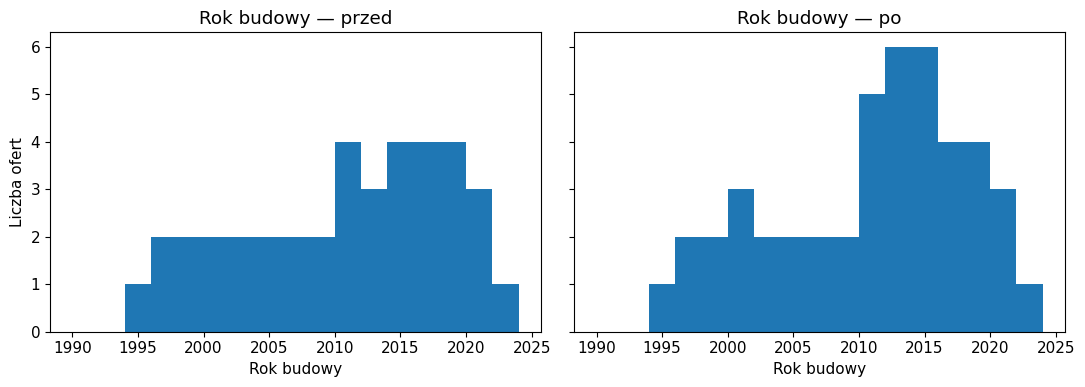

In [19]:
# TODO
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
porownanie = pd.DataFrame({
    "przed": surowe[["powierzchnia", "rok_budowy", "cena_m2"]].describe().loc[["count", "mean", "std", "min", "50%", "max"]].stack(),
    "po": mieszkania[["powierzchnia", "rok_budowy", "cena_m2"]].describe().loc[["count", "mean", "std", "min", "50%", "max"]].stack()
})
display(porownanie)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
bins = np.arange(1990, 2026, 2)
axes[0].hist(surowe["rok_budowy"].dropna(), bins=bins)
axes[0].set_title("Rok budowy — przed")
axes[1].hist(mieszkania["rok_budowy"], bins=bins)
axes[1].set_title("Rok budowy — po")
for ax in axes:
    ax.set_xlabel("Rok budowy")
axes[0].set_ylabel("Liczba ofert")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:*

odtworzenie z równania cena_total = powierzchnia × cena_m2 jest lepsze od imputacji, jeśli pozostałe dwie wartości są wiarygodne.


### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` |NaN, "brak", 0|9 |odtworzyć z cena_total/cena_m2 |powierzchnie można wyliczyć z pozostąłych danych |
| `cena_m2` |-1, -999 |2 |odtworzyć z cena_total/powierzchnia |cena z m2 wynika z ceny całkowitej i powierzchni |
| `rok_budowy` |NaN, "brak" |7 |uzupełnić medianą w grupach według miasta |uwzględnia różnicę rynków w miastach |
| `pietro` |"brak", -999 |3 |uzupełnić medianą lub oszacować na podstawie liczby pięter |pozwala uzupełnić wartość bez usuwania oferty |
| `parking` |"?"|5 |zastąpić kategorią "nieznane" |nie wiadomo czy mieszkanie ma parking czy nie |
| `balkon` |"?"|3 | zastąpić kategorią "nieznane" |nie wiadomo czy mieszkanie ma balkon czy nie |
| `stan` |	Brak formalnych braków; "很好" |0|zmienić znak na "bardzo dobry" |ujednolicenie kategorii bez zmiany znaczenia |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [20]:
# TODO
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
kompletne = surowe.dropna(subset=["rok_budowy", "cena_m2"])
korelacja_bez_brakow = kompletne["rok_budowy"].corr(kompletne["cena_m2"])

warianty_roku = {
    "mediana całościowa": surowe["rok_budowy"].fillna(surowe["rok_budowy"].median()),
    "mediana według miasta": surowe["rok_budowy"].fillna(surowe.groupby("miasto")["rok_budowy"].transform("median")),
    "mediana według stanu": surowe["rok_budowy"].fillna(surowe.groupby("stan")["rok_budowy"].transform("median"))
}
wyniki_korelacji = {"dane bez braków": korelacja_bez_brakow}
for nazwa, rok in warianty_roku.items():
    tymczasowe = surowe.copy()
    tymczasowe["rok_budowy"] = rok
    wyniki_korelacji[nazwa] = tymczasowe["rok_budowy"].corr(tymczasowe["cena_m2"])
display(pd.Series(wyniki_korelacji, name="korelacja_rok_cena_m2").to_frame())
print("Najmniejsza zmiana korelacji względem danych bez braków:",
      min(warianty_roku, key=lambda nazwa: abs(wyniki_korelacji[nazwa] - korelacja_bez_brakow)))

,korelacja_rok_cena_m2
dane bez braków,0.687207
mediana całościowa,0.655661
mediana według miasta,0.690912
mediana według stanu,0.689012


Najmniejsza zmiana korelacji względem danych bez braków: mediana według stanu


*Twoja odpowiedź:*

uzupełnianie medianą całościową, medianą według miasta i medianą według stanu może prowadzić do różnych korelacji. Najlepszym wariantem w tym zadaniu jest ten, którego korelacja jest najbliższa korelacji obliczonej na rekordach z niebrakującym rokiem budowy i ceną za m².